# ML Project - Part A: RainTomorrow

Group 58

Input: `data/raw/sensed_data.csv` (created by `sensing.py`)
Output: `data/processed/final_dataset.csv`

1. Setup and loading
2. Target variable (RainTomorrow)
3. Data understanding (EDA)
4. Data quality
5. Data preparation
6. Save final dataset

## 1. Setup and loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

RAW_FILE = Path("data/raw/sensed_data.csv")
PROCESSED_DIR = Path("data/processed")
OUTPUT_FILE = PROCESSED_DIR / "final_dataset.csv"

RAIN_THRESHOLD_MM = 1.0   # a "rainy day" is >= 1.0 mm (project definition)

LOCATIONS = ["london", "new_york", "sydney", "berlin", "tokyo", "vancouver"]
CITY_COLORS = dict(zip(LOCATIONS, sns.color_palette("colorblind", len(LOCATIONS))))

In [2]:
df = pd.read_csv(RAW_FILE, parse_dates=["date"])
print(df.shape)
df.head()

(36930, 12)


,location,date,weather_code,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_mean,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_direction_10m_dominant
0,berlin,2010-01-01,73,-1.6,-3.2,-2.5,-7.2,3.2,0.0,12.0,16.3,44
1,berlin,2010-01-02,71,-1.2,-5.7,-3.2,-7.6,1.1,0.0,9.0,15.8,324
2,berlin,2010-01-03,71,-4.9,-8.9,-6.7,-10.5,0.0,0.0,0.0,7.3,49
3,berlin,2010-01-04,3,-6.3,-9.6,-7.6,-12.0,0.0,0.0,0.0,13.0,215
4,berlin,2010-01-05,3,-5.4,-11.7,-7.7,-12.3,0.0,0.0,0.0,11.2,176


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 36930 entries, 0 to 36929
Data columns (total 12 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   location                     36930 non-null  str           
 1   date                         36930 non-null  datetime64[us]
 2   weather_code                 36930 non-null  int64         
 3   temperature_2m_max           36930 non-null  float64       
 4   temperature_2m_min           36930 non-null  float64       
 5   temperature_2m_mean          36930 non-null  float64       
 6   apparent_temperature_mean    36930 non-null  float64       
 7   precipitation_sum            36930 non-null  float64       
 8   rain_sum                     36930 non-null  float64       
 9   precipitation_hours          36930 non-null  float64       
 10  wind_speed_10m_max           36930 non-null  float64       
 11  wind_direction_10m_dominant  36930 non-null  int64  

36,930 rows, one per day per city (6 cities x 6,155 days, 2010-01-01 to 2026-11-07). No missing values at this point.

## 2. Target variable

RainTomorrow = 1 if precipitation_sum on the *next day* in the same city is >= 1.0 mm, else 0.

A few things to be careful about:
- sort by location and date first
- shift inside each city (groupby), otherwise the last day of one city would get the first day of the next city as its "tomorrow"
- make sure there are no missing days, otherwise the next row is not actually the next day
- the next-day precipitation is only used to build the target, it is not kept as a feature (that would be leakage)

In [4]:
df = df.sort_values(["location", "date"]).reset_index(drop=True)

# check that every day follows the previous one
gap_days = df.groupby("location")["date"].diff().dt.days
gaps = df.loc[gap_days.notna() & (gap_days != 1), ["location", "date"]]
print("non-consecutive days:", len(gaps))
gaps

non-consecutive days: 0


,location,date


In [5]:
next_day_precip = df.groupby("location")["precipitation_sum"].shift(-1)
df["RainTomorrow"] = (next_day_precip >= RAIN_THRESHOLD_MM).astype(int)

# the last day of each city has no tomorrow -> drop it
last_rows = next_day_precip.isna()
print(df.loc[last_rows, ["location", "date"]].to_string(index=False))
df = df.loc[~last_rows].reset_index(drop=True)
print(df.shape)

 location       date
   berlin 2026-11-07
   london 2026-11-07
 new_york 2026-11-07
   sydney 2026-11-07
    tokyo 2026-11-07
vancouver 2026-11-07
(36924, 13)


In [6]:
# sanity check: RainTomorrow of each row should match precipitation_sum of the row below it
df.loc[df.location == "london", ["location", "date", "precipitation_sum", "RainTomorrow"]].head(8)

,location,date,precipitation_sum,RainTomorrow
6154,london,2010-01-01,0.0,0
6155,london,2010-01-02,0.0,0
6156,london,2010-01-03,0.0,0
6157,london,2010-01-04,0.0,1
6158,london,2010-01-05,3.2,1
6159,london,2010-01-06,9.4,0
6160,london,2010-01-07,0.0,0
6161,london,2010-01-08,0.0,0


### Prior probability of the target

In [7]:
prior = df["RainTomorrow"].value_counts(normalize=True).sort_index()
print(prior.round(3).to_string())
print()
print(df.groupby("location")["RainTomorrow"].mean().sort_values(ascending=False).round(3).to_string())

RainTomorrow
0    0.638
1    0.362

location
vancouver    0.452
tokyo        0.366
london       0.359
new_york     0.338
berlin       0.336
sydney       0.322


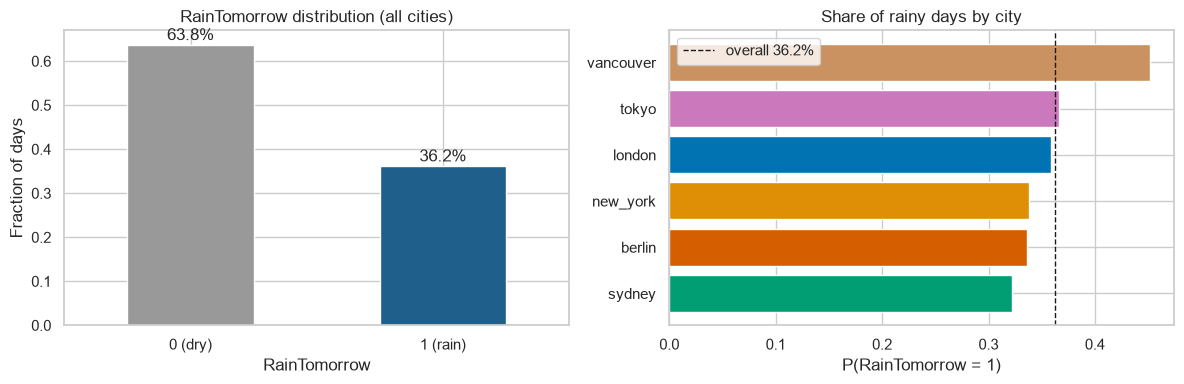

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

prior.plot(kind="bar", ax=axes[0], color=["#999999", "#1f5f8b"])
axes[0].set_title("RainTomorrow distribution (all cities)")
axes[0].set_xlabel("RainTomorrow")
axes[0].set_ylabel("Fraction of days")
axes[0].set_xticklabels(["0 (dry)", "1 (rain)"], rotation=0)
for i, v in enumerate(prior):
    axes[0].text(i, v + 0.01, f"{v:.1%}", ha="center")

by_city = df.groupby("location")["RainTomorrow"].mean().sort_values()
axes[1].barh(by_city.index, by_city.values, color=[CITY_COLORS[c] for c in by_city.index])
axes[1].axvline(prior[1], ls="--", color="k", lw=1, label=f"overall {prior[1]:.1%}")
axes[1].set_title("Share of rainy days by city")
axes[1].set_xlabel("P(RainTomorrow = 1)")
axes[1].legend()
plt.tight_layout()
plt.show()

About 36% of days are followed by a rainy day, so the classes are imbalanced (roughly 1:2) but not badly.
A model that always predicts "no rain" would already get ~64% accuracy, so in part B accuracy alone won't be a good metric.

Vancouver is clearly the wettest city (45%), Sydney the driest (32%). The other four are close to each other.

TODO: write a few more sentences about why (climate of each city).

## 3. Data understanding (EDA)

In this section we only look at the data, we don't change it. Helper columns that we need for the plots
(rain today, temperature range, wind sector, month) go into a copy called `eda`, so `df` stays clean.
The real features are built in section 5.

In [9]:
eda = df.copy()
eda["month"] = eda["date"].dt.month
eda["rain_today"] = (eda["precipitation_sum"] >= RAIN_THRESHOLD_MM).astype(int)
eda["temp_range"] = eda["temperature_2m_max"] - eda["temperature_2m_min"]

### 3.1 Data source and variable dictionary

The data comes from the Open-Meteo Historical Weather API. These are not raw measurements from a weather station.
Open-Meteo serves **reanalysis** data (mainly ERA5 from ECMWF): a physical weather model that is fed with many
observations (stations, satellites, weather balloons, aircraft) and outputs a complete, consistent value for every
point on a grid (about 9-25 km). So every value is a model estimate for the grid cell closest to the city, and the
daily variables are aggregated from hourly model values in the local time zone (`timezone=auto`).

What this means for us:
- we should expect no missing values and no broken sensors (checked in section 4),
- values are smoother than at a real station, a short local storm can be missed or spread out,
- the coordinates returned by the API are the grid point, not the exact city center.

| Variable | Meaning | Units | Type |
|---|---|---|---|
| `location` | city (6 values) | - | categorical, nominal (no order) |
| `date` | the day | date | time; not used directly as a feature, month/season are derived from it |
| `weather_code` | WMO code of the most severe weather of the day (0 clear, 3 overcast, 51-55 drizzle, 61-65 rain, 71-75 snow) | code | categorical. Stored as a number, but averaging codes means nothing. Partly ordered by severity inside a group |
| `temperature_2m_max` | max air temperature at 2 m | °C | continuous |
| `temperature_2m_min` | min air temperature at 2 m | °C | continuous |
| `temperature_2m_mean` | mean air temperature at 2 m | °C | continuous |
| `apparent_temperature_mean` | mean "feels like" temperature (wind and humidity included) | °C | continuous |
| `precipitation_sum` | total precipitation (rain + snow as water) | mm | continuous, >= 0, many zeros |
| `rain_sum` | rain only | mm | continuous, >= 0 |
| `precipitation_hours` | number of hours with precipitation | hours | discrete, 0-24 |
| `wind_speed_10m_max` | max wind speed at 10 m | km/h | continuous |
| `wind_direction_10m_dominant` | dominant direction the wind comes **from** (0 = north, 90 = east) | degrees | continuous but **circular**: 359° is next to 1° |
| `RainTomorrow` | target: 1 if tomorrow's `precipitation_sum` >= 1.0 mm, else 0 | 0/1 | binary |

### 3.2 Distributions (prior probabilities)

The target's prior was shown in section 2 (36.2% rain, 63.8% dry). Here are the distributions of three continuous
variables (density plots, KDE) and two categorical ones (bar plots).

In [10]:
df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
date,36924,2018-06-04 12:00:00,2010-01-01 00:00:00,2014-03-19 00:00:00,2018-06-04 12:00:00,2022-08-21 00:00:00,2026-11-06 00:00:00,NaN
weather_code,36924.0,32.363991,0.0,3.0,51.0,55.0,75.0,27.590422
temperature_2m_max,36924.0,16.869034,-12.7,10.5,17.3,22.9,42.0,8.257107
temperature_2m_min,36924.0,9.210308,-20.6,3.6,9.5,14.8,29.6,7.595631
temperature_2m_mean,36924.0,12.9936,-16.8,7.0,13.3,18.8,34.9,7.726088
apparent_temperature_mean,36924.0,11.293877,-21.8,3.6,11.3,18.5,38.8,9.799877
precipitation_sum,36924.0,3.188647,0.0,0.0,0.2,2.7,183.6,7.688186
rain_sum,36924.0,3.046623,0.0,0.0,0.1,2.5,183.6,7.545229
precipitation_hours,36924.0,4.307713,0.0,0.0,1.0,7.0,24.0,6.002039
wind_speed_10m_max,36924.0,19.062352,3.5,13.4,17.8,23.2,95.9,7.892334


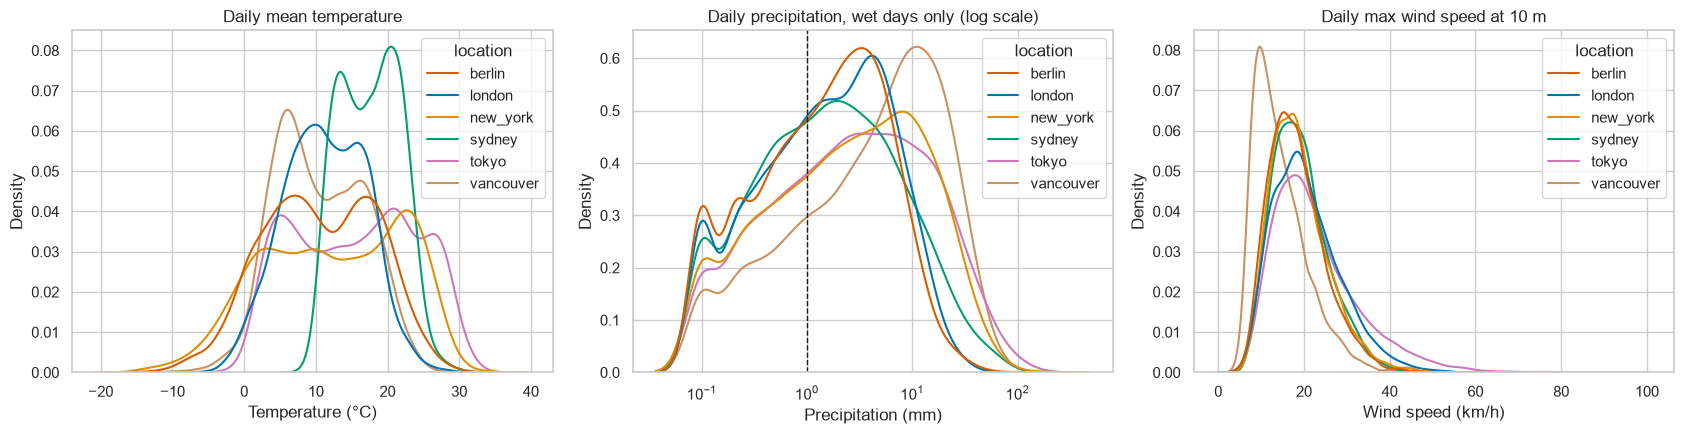

share of days with exactly 0 mm: 0.455


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# 1. mean temperature, one curve per city
sns.kdeplot(data=eda, x="temperature_2m_mean", hue="location", palette=CITY_COLORS,
            common_norm=False, ax=axes[0])
axes[0].set_title("Daily mean temperature")
axes[0].set_xlabel("Temperature (°C)")

# 2. precipitation: almost half the days are 0 mm, so the curve is drawn only for wet days, on a log x-axis
wet = eda[eda["precipitation_sum"] > 0]
sns.kdeplot(data=wet, x="precipitation_sum", hue="location", palette=CITY_COLORS,
            common_norm=False, log_scale=True, ax=axes[1])
axes[1].axvline(RAIN_THRESHOLD_MM, color="k", ls="--", lw=1)
axes[1].set_title("Daily precipitation, wet days only (log scale)")
axes[1].set_xlabel("Precipitation (mm)")

# 3. max wind speed
sns.kdeplot(data=eda, x="wind_speed_10m_max", hue="location", palette=CITY_COLORS,
            common_norm=False, ax=axes[2])
axes[2].set_title("Daily max wind speed at 10 m")
axes[2].set_xlabel("Wind speed (km/h)")

for ax in axes:
    ax.set_ylabel("Density")
plt.tight_layout()
plt.show()

print("share of days with exactly 0 mm:", round((eda["precipitation_sum"] == 0).mean(), 3))

- **Temperature:** the cities are clearly different. Berlin, New York and Tokyo have the widest curves (cold winters,
  hot summers; Tokyo has the hottest summers), London and Vancouver are narrower (mild ocean climate), and Sydney is the
  narrowest because it never gets cold. Most curves have two bumps (winter and summer), so temperature is not normally distributed.
- **Precipitation:** very skewed. 45.5% of all days have exactly 0 mm and most wet days have only a few mm, with a long
  tail of heavy days (max 183.6 mm, looked at in section 4). The dashed line is the 1 mm threshold of the target.
  Because of this skew we use Spearman (rank) correlation below and not Pearson.
- **Wind:** skewed to the right with a peak around 15-20 km/h, strong wind days are rare. Most cities overlap, except
  Vancouver, which is clearly calmer (peak around 10 km/h), and Tokyo, which has the longest tail (typhoons).

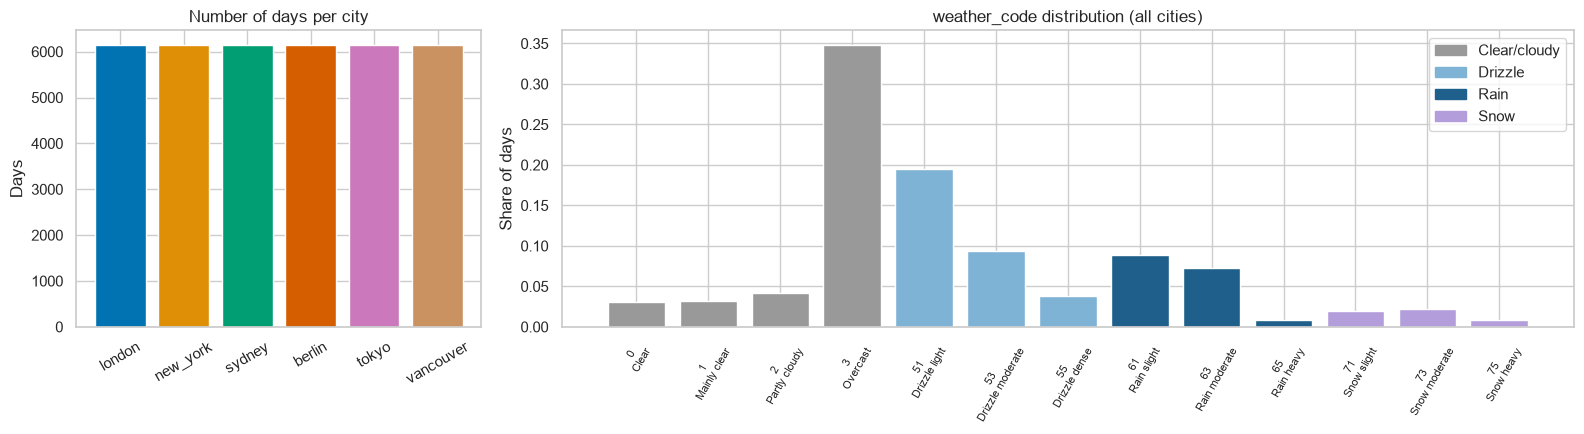

codes that appear: [0, 1, 2, 3, 51, 53, 55, 61, 63, 65, 71, 73, 75]


In [12]:
WMO_NAMES = {
    0: "Clear", 1: "Mainly clear", 2: "Partly cloudy", 3: "Overcast",
    51: "Drizzle light", 53: "Drizzle moderate", 55: "Drizzle dense",
    61: "Rain slight", 63: "Rain moderate", 65: "Rain heavy",
    71: "Snow slight", 73: "Snow moderate", 75: "Snow heavy",
}
WMO_GROUP_COLORS = {"Clear/cloudy": "#999999", "Drizzle": "#7fb3d5", "Rain": "#1f5f8b", "Snow": "#b39ddb"}

def wmo_group(code):
    if code <= 3:
        return "Clear/cloudy"
    if code <= 57:
        return "Drizzle"
    if code <= 67:
        return "Rain"
    return "Snow"

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1, 2.5]})

city_counts = eda["location"].value_counts().reindex(LOCATIONS)
axes[0].bar(city_counts.index, city_counts.values, color=[CITY_COLORS[c] for c in city_counts.index])
axes[0].set_title("Number of days per city")
axes[0].set_ylabel("Days")
axes[0].tick_params(axis="x", rotation=30)

code_share = eda["weather_code"].value_counts(normalize=True).sort_index()
labels = [f"{c}\n{WMO_NAMES[c]}" for c in code_share.index]
colors = [WMO_GROUP_COLORS[wmo_group(c)] for c in code_share.index]
axes[1].bar(labels, code_share.values, color=colors)
axes[1].set_title("weather_code distribution (all cities)")
axes[1].set_ylabel("Share of days")
axes[1].tick_params(axis="x", rotation=60, labelsize=8)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in WMO_GROUP_COLORS.values()]
axes[1].legend(handles, WMO_GROUP_COLORS.keys())

plt.tight_layout()
plt.show()

print("codes that appear:", sorted(eda["weather_code"].unique().tolist()))

- **location:** every city has exactly 6,154 days, so no city is over-represented. This is a result of how we collected
  the data, not something we learn about the weather.
- **weather_code:** only 13 of the WMO codes appear. "Overcast" (3) is the most common single code (~35%), and
  drizzle codes (51-55) together are more common than rain codes (61-65). Fog (45, 48), showers (80-82) and
  thunderstorms (95-99) never appear, probably because the daily code is derived from model output where these are rare
  at this resolution. Since many codes have few days and the numbers have no real distance between them,
  we will group them in section 5.

### 3.3 Is the dataset balanced? Is it representative?

**Balance.** The target is 36% / 64%, so it is imbalanced but not severely (about 1:2). It is not a rare-event problem,
but a model that always says "no rain" already gets 64% accuracy. In part B we will need metrics such as recall,
precision, F1 or AUC, not just accuracy. The share also differs between cities (32% Sydney to 45% Vancouver).

**Representative?** Partly:
- only 6 large cities, all in mid-latitudes, 5 in the northern hemisphere and 1 in the southern; no tropical, desert
  or mountain climates. A model trained on them should not be used for, say, Tel Aviv or Singapore.
- the values come from a model (reanalysis), not from rain gauges, so local storms may be smoothed.
- each city has the same weight, which is fine for the task (the test set will come from the same 6 cities).
- for the time dimension we checked if the rain share changes over the years:

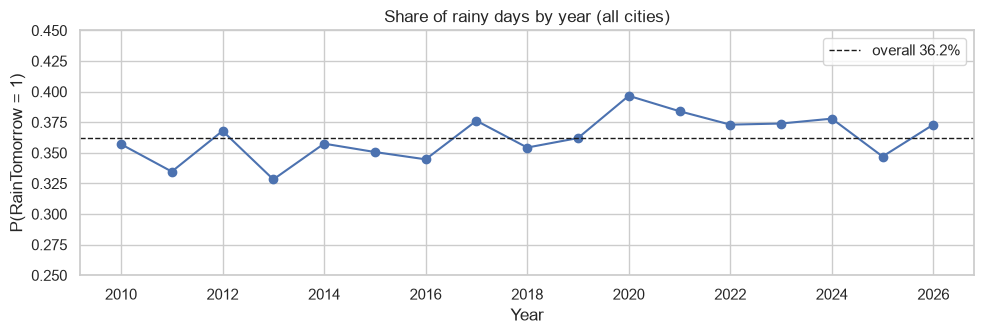

In [13]:
by_year = eda.groupby(eda["date"].dt.year)["RainTomorrow"].mean()

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(by_year.index, by_year.values, marker="o")
ax.axhline(prior[1], ls="--", color="k", lw=1, label=f"overall {prior[1]:.1%}")
ax.set_title("Share of rainy days by year (all cities)")
ax.set_xlabel("Year")
ax.set_ylabel("P(RainTomorrow = 1)")
ax.set_ylim(0.25, 0.45)
ax.legend()
plt.tight_layout()
plt.show()

The yearly share moves between 33% and 40% without a clear trend (2020-2024 are a bit higher, but 17 years is too short to call
that a climate trend; 2026 is also a partial year). So the period we collected looks stable, which is good news for
part B, where the model will be tested on future days.

### 3.4 Correlations between the numeric variables

We use Spearman correlation because precipitation is very skewed and Spearman only looks at the ranks.
`weather_code` is left out (it is a category, not a quantity) and so is the wind direction (circular: 350° and 10° are
almost the same direction but are far apart as numbers, so a correlation coefficient means nothing). Both are looked at
separately below.

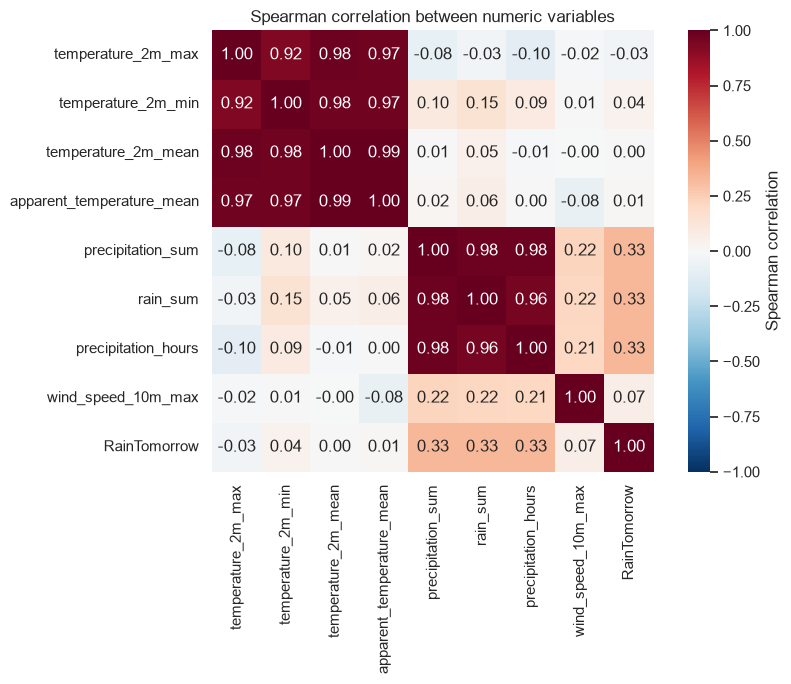

In [14]:
numeric_cols = [
    "temperature_2m_max", "temperature_2m_min", "temperature_2m_mean", "apparent_temperature_mean",
    "precipitation_sum", "rain_sum", "precipitation_hours", "wind_speed_10m_max", "RainTomorrow",
]
corr = eda[numeric_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={"label": "Spearman correlation"})
ax.set_title("Spearman correlation between numeric variables")
plt.tight_layout()
plt.show()

Two clear blocks:
- **The 4 temperature variables** are almost the same information (0.92-0.99). Mean temperature is basically
  (max + min) / 2, and the apparent temperature follows it closely.
- **The 3 precipitation variables** (`precipitation_sum`, `rain_sum`, `precipitation_hours`) are 0.96-0.98 with each other.

Against the target, only the precipitation block shows a real relation (0.33): rain today goes with rain tomorrow.
The temperatures are around 0 and wind speed is weak (0.07). A correlation near 0 does not prove a variable is useless,
it only says there is no monotonic relation over all cities together. We check that below.

### 3.5 Interesting relations

#### 3.5.1 Rain today -> rain tomorrow (expected)
Weather systems usually last more than one day, so we expected rain to "persist".

           dry today  rain today
location                        
london         0.258       0.539
new_york       0.280       0.453
sydney         0.210       0.559
berlin         0.242       0.521
tokyo          0.271       0.531
vancouver      0.251       0.696

rain_today
dry today     0.252
rain today    0.557
Name: RainTomorrow, dtype: float64


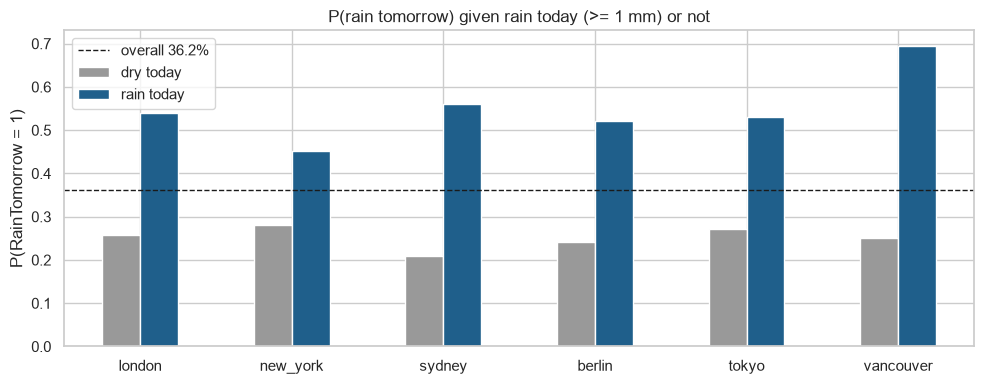

In [15]:
persist = eda.pivot_table(index="location", columns="rain_today", values="RainTomorrow").reindex(LOCATIONS)
persist.columns = ["dry today", "rain today"]
print(persist.round(3))
print()
print(eda.groupby("rain_today")["RainTomorrow"].mean().round(3).rename({0: "dry today", 1: "rain today"}))

ax = persist.plot(kind="bar", figsize=(10, 4), color=["#999999", "#1f5f8b"], rot=0)
ax.axhline(prior[1], ls="--", color="k", lw=1, label=f"overall {prior[1]:.1%}")
ax.set_title("P(rain tomorrow) given rain today (>= 1 mm) or not")
ax.set_xlabel("")
ax.set_ylabel("P(RainTomorrow = 1)")
ax.legend()
plt.tight_layout()
plt.show()

After a rainy day the chance of rain tomorrow is 55.7%, after a dry day only 25.2%, more than double. This holds in every
city. It is strongest in Vancouver (70% after a rainy day: long rainy periods from the Pacific) and weakest in New York
(45%: rain there comes more often from short, fast-moving systems). So "rain today" is a strong and simple feature, and
the interaction with the city also matters.

#### 3.5.2 Season and city (expected in general, the details are interesting)

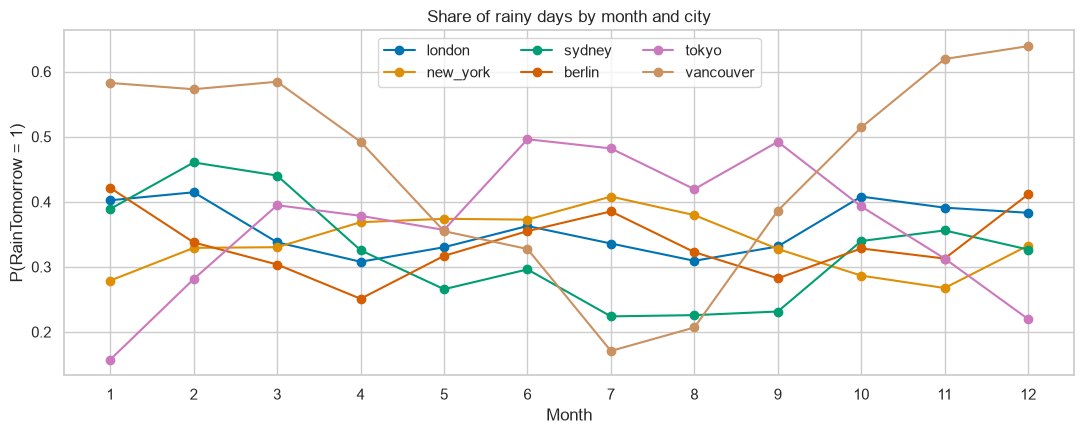

In [16]:
monthly = eda.pivot_table(index="month", columns="location", values="RainTomorrow")

fig, ax = plt.subplots(figsize=(11, 4.5))
for city in LOCATIONS:
    ax.plot(monthly.index, monthly[city], marker="o", label=city, color=CITY_COLORS[city])
ax.set_title("Share of rainy days by month and city")
ax.set_xlabel("Month")
ax.set_ylabel("P(RainTomorrow = 1)")
ax.set_xticks(range(1, 13))
ax.legend(ncol=3)
plt.tight_layout()
plt.show()

Each city has its own yearly cycle, and some go in opposite directions:
- **Vancouver**: very wet in winter (64% in December) and dry in summer (17% in July).
- **Tokyo**: the opposite, wet in summer (rainy season in June and typhoons in September, 42-50% from June to September) and dry in winter (16% in January).
- **Sydney** (southern hemisphere): wettest in February-March, driest in July-September.
- **London, Berlin, New York**: much flatter, between 25% and 42% all year.

So month alone is not useful (the patterns cancel out when all cities are mixed), but month *together with* city is.
For a model this means season features have to be combined with the location, and season has to be defined by
hemisphere for Sydney.

#### 3.5.3 Wind direction and rain, per city (partly unexpected)
The wind direction is circular, so we split it into 8 sectors (N, NE, ...) and draw a polar plot of the rain share per sector.

location     berlin  london  new_york  sydney  tokyo  vancouver
wind_sector                                                    
N              0.26    0.16      0.22    0.35   0.34       0.25
NE             0.21    0.20      0.47    0.32   0.47       0.52
E              0.26    0.29      0.54    0.39   0.52       0.72
SE             0.31    0.43      0.60    0.47   0.52       0.53
S              0.40    0.55      0.50    0.47   0.41       0.46
SW             0.47    0.45      0.35    0.29   0.31       0.31
W              0.36    0.32      0.21    0.15   0.24       0.22
NW             0.22    0.27      0.19    0.17   0.19       0.18


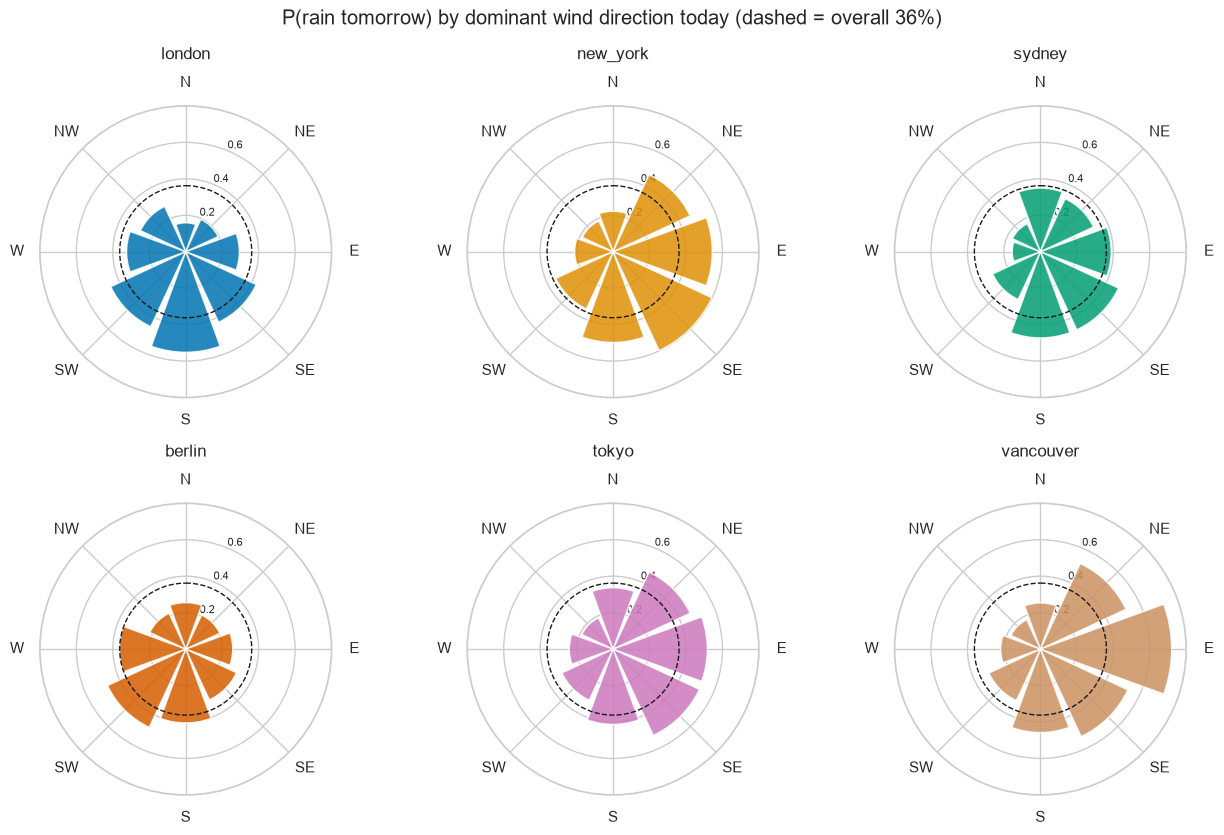

In [17]:
SECTORS = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
# shift by 22.5° so that "N" covers 337.5°-22.5°, then cut into 8 slices of 45°
shifted = (eda["wind_direction_10m_dominant"] + 22.5) % 360
eda["wind_sector"] = pd.cut(shifted, bins=range(0, 361, 45), labels=SECTORS, right=False)

sector_rate = eda.pivot_table(index="wind_sector", columns="location", values="RainTomorrow", observed=False)
print(sector_rate.round(2))

angles = np.deg2rad(np.arange(0, 360, 45))
circle = np.linspace(0, 2 * np.pi, 100)
fig, axes = plt.subplots(2, 3, figsize=(13, 8.5), subplot_kw={"projection": "polar"})
for ax, city in zip(axes.flat, LOCATIONS):
    ax.bar(angles, sector_rate[city].values, width=np.deg2rad(40), color=CITY_COLORS[city], alpha=0.85)
    ax.plot(circle, [prior[1]] * len(circle), "k--", lw=1)
    ax.set_theta_zero_location("N")   # north on top
    ax.set_theta_direction(-1)        # clockwise, like a compass
    ax.set_xticks(angles)
    ax.set_xticklabels(SECTORS)
    ax.set_ylim(0, 0.8)
    ax.set_yticks([0.2, 0.4, 0.6])
    ax.set_rlabel_position(22.5)
    ax.tick_params(axis="y", labelsize=8)
    ax.set_title(city, pad=12)
fig.suptitle("P(rain tomorrow) by dominant wind direction today (dashed = overall 36%)")
plt.tight_layout()
plt.show()

The direction that brings rain is different in every city, and in all of them the difference is large (from under 20% to over 50%):
- **London, Berlin**: rain comes with south and south-west winds (from the Atlantic), north and north-west winds are dry.
  This is what we expected.
- **New York**: east and south-east winds (from the ocean, ahead of coastal storms) give 54-60%; north-west winds (dry
  continental air) only 19%.
- **Vancouver**: the surprise. We expected west winds from the Pacific to bring rain, but the wettest direction is
  **east** (72%) and west is dry (22%). A likely reason is the local geography: before a Pacific storm arrives, the
  surface wind in the Strait of Georgia blows from the east/south-east, and after it passes it turns west/north-west with clearing.
- **Tokyo**: north-east to south-east winds (from the Pacific) are wet (47-52%), north-west winds (cold, dry winter
  monsoon from the continent) only 19%.
- **Sydney**: south and south-east (from the sea) are wet, west winds (from the dry inland) are the driest (15%).

This explains why the overall correlation of wind direction with the target looked weak: the effect is strong but
different in every city, so it cancels out. Wind direction must be encoded in a circular way (sin/cos or u/v) and combined with the location.

#### 3.5.4 Daily temperature range and rain (less expected)
Temperature itself has almost no correlation with the target. But clouds keep the day cooler and the night warmer,
so a cloudy day should have a smaller max - min range.

                count  mean   std  min  25%  50%   75%   max
RainTomorrow                                                
0             23549.0  8.11  3.12  0.5  5.9  7.9  10.1  26.2
1             13375.0  6.87  3.13  0.6  4.5  6.5   8.8  20.8


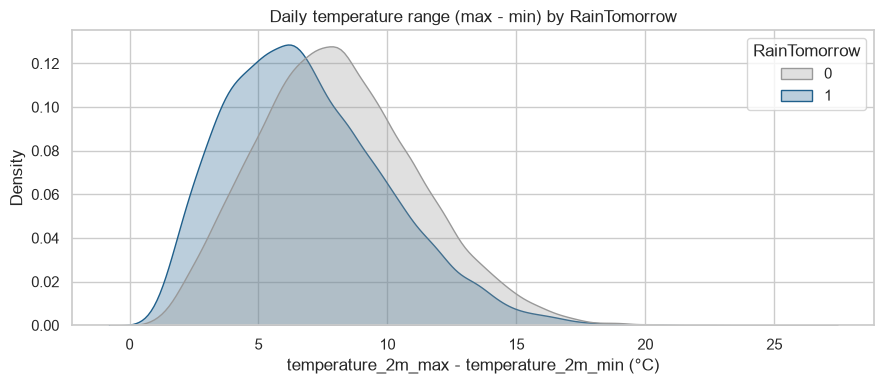

In [18]:
print(eda.groupby("RainTomorrow")["temp_range"].describe().round(2))

fig, ax = plt.subplots(figsize=(9, 4))
sns.kdeplot(data=eda, x="temp_range", hue="RainTomorrow", common_norm=False,
            palette={0: "#999999", 1: "#1f5f8b"}, fill=True, alpha=0.3, ax=ax)
ax.set_title("Daily temperature range (max - min) by RainTomorrow")
ax.set_xlabel("temperature_2m_max - temperature_2m_min (°C)")
ax.set_ylabel("Density")
plt.tight_layout()
plt.show()

Days before a rainy day have a smaller temperature range (median 6.5 °C vs 7.9 °C). The two curves overlap a lot,
so this is not a strong feature alone, but it carries information that max, min and mean separately do not show
clearly. This is a good candidate for a derived feature (`temp_range`) in section 5.

### 3.6 Which features do we expect to affect the target?

From basic weather knowledge we expected: today's precipitation (and how many hours it rained), the type of weather
(`weather_code`), wind direction, season, location, and maybe wind speed (storms) and temperature range (clouds).
Below we compare the distribution of a few variables on days before rain vs. days before no rain.

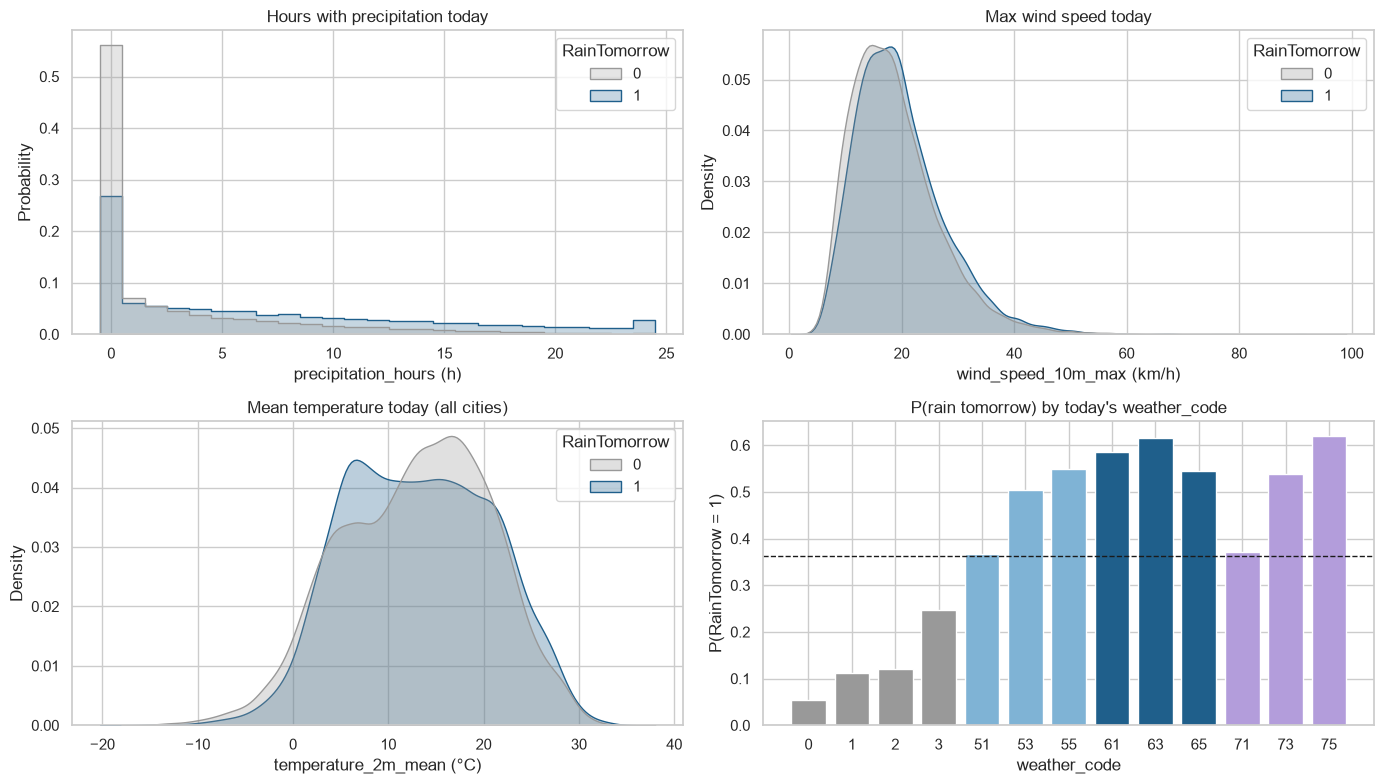

              precipitation_hours  wind_speed_10m_max  temperature_2m_mean
RainTomorrow                                                              
0                             0.0                17.4                 13.5
1                             5.0                18.5                 13.0


In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
palette = {0: "#999999", 1: "#1f5f8b"}

sns.histplot(data=eda, x="precipitation_hours", hue="RainTomorrow", discrete=True, stat="probability",
             common_norm=False, palette=palette, element="step", ax=axes[0, 0])
axes[0, 0].set_title("Hours with precipitation today")
axes[0, 0].set_xlabel("precipitation_hours (h)")

sns.kdeplot(data=eda, x="wind_speed_10m_max", hue="RainTomorrow", common_norm=False,
            palette=palette, fill=True, alpha=0.3, ax=axes[0, 1])
axes[0, 1].set_title("Max wind speed today")
axes[0, 1].set_xlabel("wind_speed_10m_max (km/h)")

sns.kdeplot(data=eda, x="temperature_2m_mean", hue="RainTomorrow", common_norm=False,
            palette=palette, fill=True, alpha=0.3, ax=axes[1, 0])
axes[1, 0].set_title("Mean temperature today (all cities)")
axes[1, 0].set_xlabel("temperature_2m_mean (°C)")

code_rate = eda.groupby("weather_code")["RainTomorrow"].mean()
axes[1, 1].bar([str(c) for c in code_rate.index], code_rate.values,
               color=[WMO_GROUP_COLORS[wmo_group(c)] for c in code_rate.index])
axes[1, 1].axhline(prior[1], ls="--", color="k", lw=1)
axes[1, 1].set_title("P(rain tomorrow) by today's weather_code")
axes[1, 1].set_xlabel("weather_code")
axes[1, 1].set_ylabel("P(RainTomorrow = 1)")

plt.tight_layout()
plt.show()

print(eda.groupby("RainTomorrow")[["precipitation_hours", "wind_speed_10m_max", "temperature_2m_mean"]].median())

- **precipitation_hours**: the strongest one. Before a dry day most days have 0 hours of precipitation; before a rainy
  day the distribution is spread over many hours (median 5 h vs 0 h).
- **weather_code**: a clear staircase. After a clear day (0) only 5% rain tomorrow, after overcast (3) 25%, light
  drizzle (51) and light snow (71) are about the average, and moderate/heavy drizzle, rain and snow are 50-62%.
  So the code carries real information. Grouping it by type and intensity should keep most of it.
- **wind speed**: slightly higher before rainy days (median 18.5 vs 17.4 km/h). A weak effect.
- **mean temperature**: the two curves are similar, with small differences in shape (more rainy days around 5-10 °C)
  that probably come from mixing cities, e.g. Vancouver is both cool and often rainy. Over all cities together,
  temperature alone says little about rain tomorrow. It may still help together with city and season.

Together with 3.5: location, season, wind direction and rain today are the features we expect a model to use most.

### 3.7 Which variables could be removed?

From the correlation matrix our assumption was:
1. the 4 temperature variables are redundant, one (plus the range) is enough;
2. `rain_sum` is the same as `precipitation_sum` except on snow days.

Checking assumption 2: how often are they different, and where?

days where precipitation_sum > rain_sum, share per city:
location
berlin       0.076
london       0.023
new_york     0.066
sydney       0.000
tokyo        0.024
vancouver    0.098
dtype: float64

weather codes on those days:
weather_code
71    628
73    816
75    321
Name: count, dtype: int64


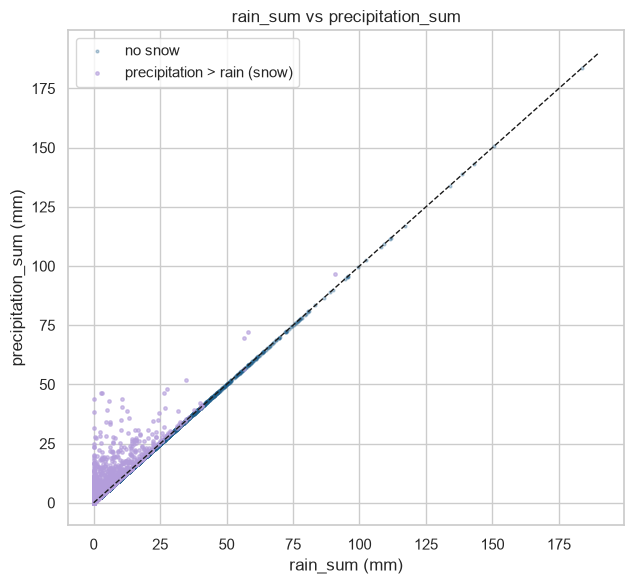

In [20]:
snow_part = eda["precipitation_sum"] - eda["rain_sum"]
has_snow = snow_part > 0.05   # small tolerance for rounding

print("days where precipitation_sum > rain_sum, share per city:")
print(has_snow.groupby(eda["location"]).mean().round(3))
print()
print("weather codes on those days:")
print(eda.loc[has_snow, "weather_code"].value_counts().sort_index())

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(eda.loc[~has_snow, "rain_sum"], eda.loc[~has_snow, "precipitation_sum"], s=4, alpha=0.3,
           color="#1f5f8b", label="no snow")
ax.scatter(eda.loc[has_snow, "rain_sum"], eda.loc[has_snow, "precipitation_sum"], s=6, alpha=0.6,
           color="#b39ddb", label="precipitation > rain (snow)")
ax.plot([0, 190], [0, 190], "k--", lw=1)
ax.set_title("rain_sum vs precipitation_sum")
ax.set_xlabel("rain_sum (mm)")
ax.set_ylabel("precipitation_sum (mm)")
ax.legend()
plt.tight_layout()
plt.show()

Almost all points are on the diagonal (precipitation = rain). The days off the diagonal are exactly the snow codes
(71, 73, 75): 7-10% of days in Vancouver, Berlin and New York, about 2% in London and Tokyo, never in Sydney. So `rain_sum` adds almost nothing beyond `precipitation_sum`, except the
information "part of it was snow", which can be kept as a small derived feature. The target is defined on
`precipitation_sum`, so that is the one to keep.

For the temperatures, the correlation (0.92-0.99) already confirms assumption 1. What is not fully redundant is the
*difference* between them: max - min (3.5.4) and apparent - mean (wind chill / humidity).

The actual decisions (what to drop, what to add) are made in section 5.

## 4. Data quality

TODO

## 5. Data preparation

TODO

## 6. Save final dataset

In [21]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
df.to_csv(OUTPUT_FILE, index=False)
print(OUTPUT_FILE, df.shape)
print(list(df.columns))

data\processed\final_dataset.csv (36924, 13)
['location', 'date', 'weather_code', 'temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'apparent_temperature_mean', 'precipitation_sum', 'rain_sum', 'precipitation_hours', 'wind_speed_10m_max', 'wind_direction_10m_dominant', 'RainTomorrow']
